In [1]:
from typing import TypedDict
from dotenv import load_dotenv
from langchain_core.messages import SystemMessage, HumanMessage
from langchain_openai import ChatOpenAI
from langgraph.graph import StateGraph, START, END
load_dotenv()  # Load environment variables from .env file

True

In [26]:
class BlogState(TypedDict):
    topic: str
    title: str
    content: str
    score: float

In [27]:
model = ChatOpenAI(
    model="gpt-4o-mini",
    temperature=0,
    max_tokens=500, # type: ignore
    timeout=30,
    max_retries=2,
)

In [28]:
def write_blog_title(state: dict) -> dict:
    topic = f"Title: {state['topic']}"
    response = model.invoke([SystemMessage(content="You are a helpful assistant that generates blog titles " \
    "based on the given topic. Write only one most suitable title."), HumanMessage(content=topic)])
    return {"title": response.content}

In [31]:
def write_blog_content(state: dict) -> dict:
    topic = f"Title: {state['topic']}"
    title = f"Title: {state['title']}"
    content = f"Topic: {topic}\nTitle: {title}"
    response = model.invoke([SystemMessage(content="You are a helpful assistant that generates blog content " \
    "based on the given topic and title. The content should be engaging and informative. Keep the length between 100 and 200 words."), HumanMessage(content=content)])
    return {"content": response.content}

In [32]:
def evaluate_content(state: dict) -> dict:
    content = f"Content: {state['content']}"
    response = model.invoke([SystemMessage(content="You are a helpful assistant that scores the quality of the given blog content based on the title" \
    "and topic "\
    "on a scale of 0 to 10, where 0 is the worst and 10 is the best. Provide only the score as a number." \
    "Topic: {state['topic']} \n Title: {state['title']} \n Content: {state['content']}"), HumanMessage(content=content)])
    score = float(response.content.strip()) # type: ignore
    return {"score": score}

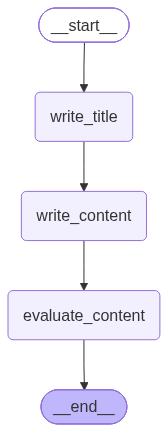

In [33]:
graph = StateGraph(BlogState);

graph.add_node('write_title', write_blog_title) # type: ignore
graph.add_node('write_content', write_blog_content) # type: ignore
graph.add_node('evaluate_content', evaluate_content) # type: ignore

graph.add_edge(START, 'write_title')
graph.add_edge('write_title', 'write_content')
graph.add_edge('write_content', 'evaluate_content')
graph.add_edge('evaluate_content', END)

graph.compile()

In [34]:
workflow = graph.compile()
result = workflow.invoke({"topic": "The future of QA Role in AI Era in IT Industry"}) # type: ignore
print('Content:', result['content'])
print('------------------------------------------------------------------------------------')
print('Score:', result['score'])

Content: **Embracing Change: The Evolving Role of QA in the AI-Driven IT Landscape**

As artificial intelligence continues to reshape the IT industry, the role of Quality Assurance (QA) is undergoing a significant transformation. Traditionally focused on manual testing and bug detection, QA professionals are now becoming integral players in the development of AI-driven applications. 

In this new landscape, QA teams are expected to adapt by embracing automation and machine learning tools that enhance testing efficiency and accuracy. Automated testing frameworks powered by AI can analyze vast amounts of data, identify patterns, and predict potential issues before they arise, allowing QA professionals to focus on more strategic tasks.

Moreover, the rise of AI necessitates a shift in skill sets. QA specialists must now be proficient in data analysis, understand AI algorithms, and possess a strong grasp of ethical considerations surrounding AI technologies. This evolution not only enhance